<a href="https://colab.research.google.com/github/Yyysf5810/ml4ss-shaoyu/blob/main/student_demo/Shaoyu_Feng/week03_01_Shaoyu_Feng.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STATS 201 Week 3 · 01 Measurement

**Question.** Why can the same stored answer index refer to two different labels?

**How to work.** In Colab, choose **File → Save a copy in Drive**. Run the cells in order on CPU. Read the saved default outputs if Hugging Face is temporarily unavailable. Start with FOCUS = "both". Then display either row on its own.

For Ed, share one figure or panel, a view-access link to your Colab copy, your interpretation and one check. The result displays inline.

## 1 · Define the observed label

Each record pairs a robot image with a question, choices and a stored answer. The question asks whether the black object has been moved from the bowl into the box. Read the choices and consider what evidence in the frame would support a claim of completion. The Prediction lab trains on the explicit **Yes** and **No** reference categories.

### Measurement pseudocode and intuition

The question and the options define the measurement. Here the question asks whether the robot completed the task in the selected frame. Each image–question pair stores the chosen answer as a position in its own option list. Decoding is like reading a survey answer against the exact form the respondent saw.

```text
Load the two target image–question records by ID
Select the records to display using FOCUS
FOR each displayed record i
    Read its ordered choices
    Convert the choices from text to a list if needed
    Read its zero-based answer position k
    Set reference label y[i] to choices[k]
    Display the row and highlight position k
END FOR
```

The rule is $y_i=\mathrm{choices}_i[\mathrm{correct\_answer}_i]$. Here $i$ identifies the record and `correct_answer` gives the position $k_i$ **within that record**. Position 0 is the first choice and position 2 is the third.

In [5]:
# Read and run. The data loader makes public Hugging Face requests.

import json
import time
from io import BytesIO
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as NotebookImage, display

import ast

DATA_SERVER = "https://datasets-server.huggingface.co"
ROBOT = "keplerccc/Robo2VLM-1"
TARGET_IDS = ("14652_q29", "14652_q35")

def read_url(url):
    for attempt in range(3):
        try:
            with urlopen(url, timeout=25) as response:
                return response.read()
        except (URLError, TimeoutError) as error:
            if isinstance(error, HTTPError) and error.code not in {429, 500, 502, 503, 504}:
                raise RuntimeError(f"Hugging Face returned HTTP {error.code}. Rerun the data cell.") from error
            if attempt == 2:
                raise RuntimeError("Hugging Face is unavailable. The saved default outputs can support discussion.") from error
            time.sleep(2 ** attempt)

def page(dataset, offset=0, first=False):
    params = {"dataset": dataset, "config": "default", "split": "train"}
    endpoint = "first-rows" if first else "rows"
    if not first:
        params.update(offset=offset, length=100)
    return json.loads(read_url(f"{DATA_SERVER}/{endpoint}?{urlencode(params)}"))["rows"]

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

In [6]:
# Read and run. Each row has its own choice order.
def reference_answer(row):
    choices = row["choices"]
    choices = ast.literal_eval(choices) if isinstance(choices, str) else choices
    return choices[row["correct_answer"]]

first_robot = [entry["row"] for entry in page(ROBOT, first=True)]
targets = [next(row for row in first_robot if row["id"].endswith(key)) for key in TARGET_IDS]

## 2 · Decode and display the result

**Your turn.** Predict the reference for each row before running the default. Then set FOCUS to **"q29"** or **"q35"** to inspect one row at a time.

,Frame,Stored index,0,1,2,3,Reference
0,14652_q35,2,No,Cannot be determined,Yes,Task was not attempted,Yes


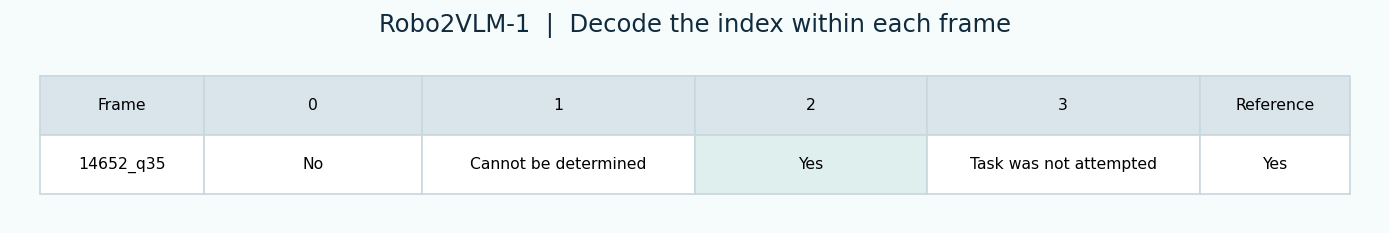

In [7]:
# Your turn. Keep the default first. Then try "q29" or "q35".
FOCUS = "q35"  # "both", "q29" or "q35"
assert FOCUS in {"both", "q29", "q35"}

visible = [row for row in targets if FOCUS == "both" or row["id"].endswith(FOCUS)]
records = []
for row in visible:
    options = ast.literal_eval(row["choices"]) if isinstance(row["choices"], str) else row["choices"]
    records.append({
        "Frame": "_".join(row["id"].split("_")[-2:]),
        "Stored index": row["correct_answer"],
        **{str(i): label for i, label in enumerate(options)},
        "Reference": reference_answer(row),
    })
measured = pd.DataFrame(records)
display(measured)

# The highlighted column marks the stored index in each row.
cols = ["Frame", "0", "1", "2", "3", "Reference"]
colors = [["#deefed" if col == str(row["Stored index"]) else "#ffffff"
           for col in cols] for row in records]
fig, ax = plt.subplots(figsize=(11, 1.75), layout="constrained", facecolor="#f6fbfb")
ax.axis("off")
t = ax.table(cellText=measured[cols].values, colLabels=cols, cellColours=colors,
             colColours=["#d9e5ea"]*len(cols), cellLoc="center",
             colWidths=[.12,.16,.20,.17,.20,.11], bbox=[.02,.15,.96,.66])
t.auto_set_font_size(False)
t.set_fontsize(9)
for cell in t.get_celld().values():
    cell.set_edgecolor("#c9d8df")
ax.set_title("Robo2VLM-1  |  Decode the index within each frame", color="#102b3d", fontsize=14)
show_figure(fig)

### Read the numbers and highlighted table

| Record | Stored position | What the position selects | Recorded reference $y_i$ |
|---|---:|---|---|
| `14652_q29` | 2 | Third choice on its own row | No |
| `14652_q35` | 2 | Third choice on its own row | Yes |

The display columns 0 through 3 label option positions. The highlighted cell shows where the lookup lands in each row. The decoded answer is a **category**, such as Yes, No, Task was not attempted or Cannot be determined. Those categories carry the meaning you would count across records. With `FOCUS = "q35"`, the display shows the single q35 row and highlights its Yes choice.

## Conclusions and assumptions

**What the results support.** Decode each row before comparing answers across frames or counting outcomes across forms. The two examples give one recorded No and one recorded Yes. The Prediction lab uses these recorded references as the observed labels when checking its predictions.

**What the interpretation assumes.** The saved option order corresponds to the row's answer position, the index is within that list, and the recorded reference applies the completion question consistently. Review whether the image and annotation support that definition of completion. Both rows come from one robot trajectory. To estimate a completion rate, first define the population and sample suitable trajectories.

## Sources and transfer

Which label definition or observation unit would your own project document? Continue to [Prediction in Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/03-prediction/week03_03_robot_prediction.ipynb) to compare model outputs with these references.

- Chen et al. (2025), [Robo2VLM](https://papers.neurips.cc/paper_files/paper/2025/hash/1f467c3e37abf9f86c78f44c6a27ee7c-Abstract-Datasets_and_Benchmarks_Track.html), NeurIPS Datasets and Benchmarks.
- [Robo2VLM-1 data and image–text preview](https://huggingface.co/datasets/keplerccc/Robo2VLM-1). The dataset card reports the Apache 2.0 license.
- [04 Evaluation Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/04-evaluation/week03_04_tabarena_evaluation.ipynb) · [TabArena case guide](https://github.com/sunshineluyao/ml4ss/blob/main/modules/04-evaluation/README.md).